In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow.keras import layers, Sequential


from src.datasets import create_datasets, class_names
from src.ViT_model_definitions import build_small_vit

2026-10-22 11:33:04.434616: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-22 11:33:04.451426: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-22 11:33:04.456531: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    device = "/GPU:0"
    print(f"Using GPU: {gpus[0]}")
else:
    device = "/CPU:0"
    print("No GPU detected. Using CPU.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1792668785.591679    2516 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668785.599984    2516 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668785.602780    2516 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


### 01. Hyperparameters and dataset setup

In [3]:
IMG_SIZE = 64
CHANNELS = 3 
BATCH_SIZE = 32
LR = 0.001
EPOCHS = 30  # Change as needed.


models_path = Path("models")

In [4]:
train_ds, val_ds, test_ds = create_datasets()

Found 4200 files belonging to 2 classes.


I0000 00:00:1792668785.840574    2516 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668785.846286    2516 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668785.849848    2516 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668786.017482    2516 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Found 900 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


### 02. Create the ViT model

In [5]:
vit_model = build_small_vit(
    image_size=IMG_SIZE,
    patch_size=8,
    embed_dim=64,
    num_heads=4,
    mlp_dim=128,
    num_transformer_layers=2,
    dropout=0.1,
    num_classes=len(class_names)
)

vit_model.summary()

Model: "small_vit"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_embedding                 │ (None, 64, 64)         │        12,352 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding          │ (None, 64, 64)         │         4,096 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,522 (326.26 KB)

 Trainable params: 83,522 (326.26 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 03. Train the pure ViT model

In [7]:
# Create the ModelCheckpoint callback
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(filepath=models_path / "ai_capstone_keras_pure_vit_model.keras",
                                monitor='val_loss',      # or 'val_accuracy'
                                mode='min',              # 'min' for loss, 'max' for accuracy
                                save_best_only=True,
                                verbose=1
                               )

In [8]:
history_vit = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    callbacks=[checkpoint_cb],
    epochs=EPOCHS
)

Epoch 1/30


I0000 00:00:1792668790.781647    2597 service.cc:146] XLA service 0x78ffac0093c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792668790.781692    2597 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5


 24/132 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7170 - loss: 0.5839

I0000 00:00:1792668797.869857    2597 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8744 - loss: 0.2853
Epoch 1: val_loss improved from inf to 0.04239, saving model to models/ai_capstone_keras_pure_vit_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 21s 77ms/step - accuracy: 0.8749 - loss: 0.2843 - val_accuracy: 0.9867 - val_loss: 0.0424
Epoch 2/30
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9729 - loss: 0.0739
Epoch 2: val_loss improved from 0.04239 to 0.03296, saving model to models/ai_capstone_keras_pure_vit_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9730 - loss: 0.0736 - val_accuracy: 0.9911 - val_loss: 0.0330
Epoch 3/30
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9791 - loss: 0.0578
Epoch 3: val_loss improved from 0.03296 to 0.02978, saving model to models/ai_capstone_keras_pure_vit_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9792 - loss: 0.0576 - val_accuracy: 0.9878 - val_loss: 0.0298
Epoch 4/30
124/132 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accurac

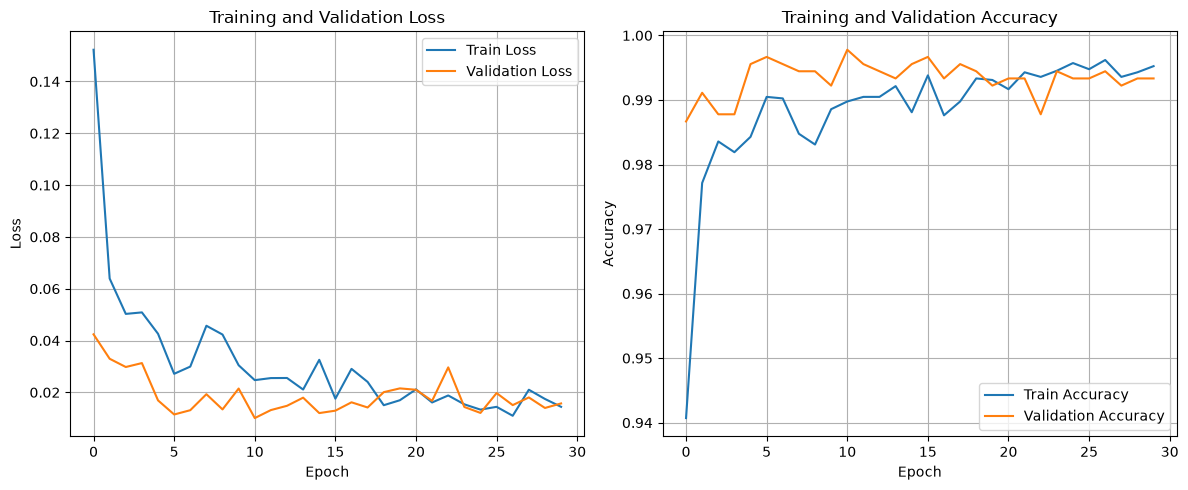

In [9]:
# Plot loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_vit.history["loss"], label="Train Loss")
plt.plot(history_vit.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

# Plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history_vit.history["accuracy"], label="Train Accuracy")
plt.plot(history_vit.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
vit_model = tf.keras.models.load_model( models_path / "ai_capstone_keras_pure_vit_model.keras")
print(vit_model.evaluate(val_ds, verbose=1))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:372: UserWarning: `build()` was called on layer 'patch_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:372: UserWarning: `build()` was called on layer 'transformer_block', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:372: UserWarning: `build()` was called on layer 'transformer_block_1', however t

29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9983 - loss: 0.0100
[0.010067177005112171, 0.9977777600288391]


### Evaluate

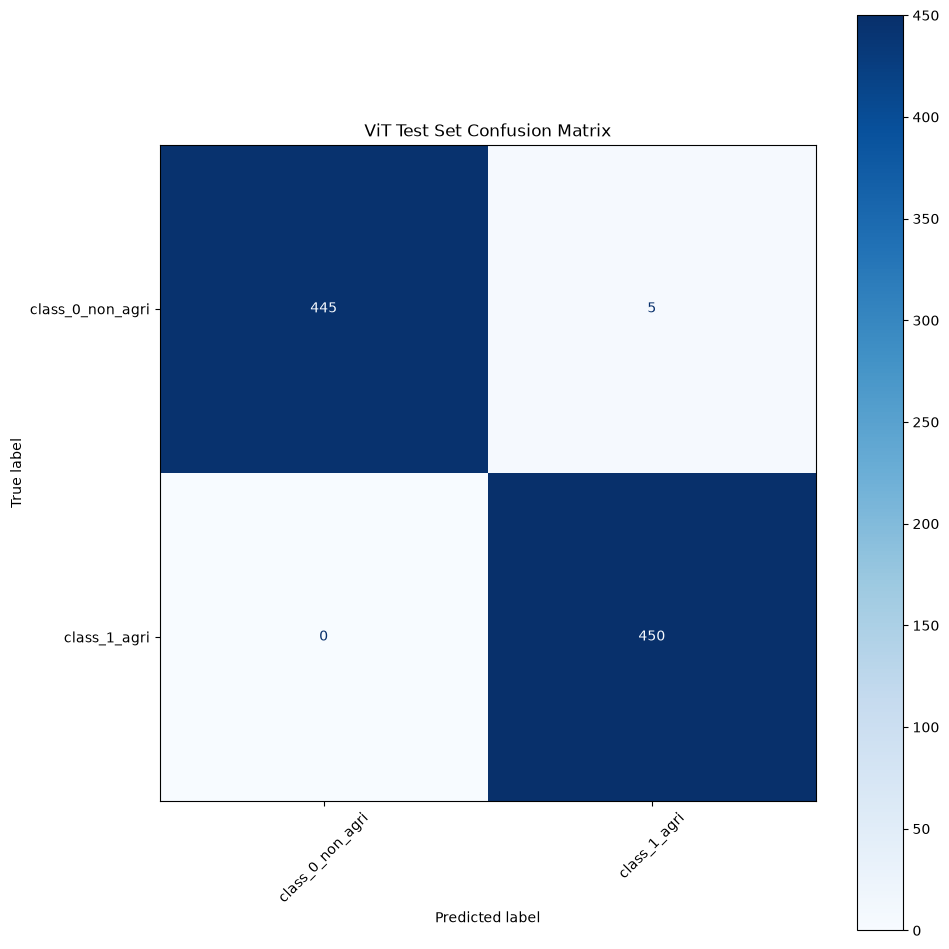

ViT Test Set Classification Report:
                  precision    recall  f1-score   support

class_0_non_agri     1.0000    0.9889    0.9944       450
    class_1_agri     0.9890    1.0000    0.9945       450

        accuracy                         0.9944       900
       macro avg     0.9945    0.9944    0.9944       900
    weighted avg     0.9945    0.9944    0.9944       900

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9940 - loss: 0.0144
Test loss: 0.0146
Test accuracy: 0.9944


In [11]:
# 1. Get true labels and model predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    # True labels
    y_true.extend(labels.numpy())

    # Model predictions: probabilities/scores for each class
    predictions = vit_model.predict(images, verbose=0)

    # Predicted class = index with highest score
    predicted_classes = np.argmax(predictions, axis=1)
    y_pred.extend(predicted_classes)

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Confusion matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("ViT Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

# 3. Classification report
print("ViT Test Set Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# 4. Evaluate test loss and accuracy
test_loss, test_accuracy = vit_model.evaluate(test_ds, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

In [12]:

# Get class names

misclassified_images = []
misclassified_true = []
misclassified_pred = []
misclassified_conf = []

# Go through the entire test set
for images, labels in test_ds:
    predictions = vit_model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)
    confidences = np.max(predictions, axis=1)

    for i in range(len(images)):
        if predicted_classes[i] != labels[i].numpy():
            misclassified_images.append(images[i].numpy())
            misclassified_true.append(labels[i].numpy())
            misclassified_pred.append(predicted_classes[i])
            misclassified_conf.append(confidences[i])

print(f"Misclassified images: {len(misclassified_images)}")

Misclassified images: 5


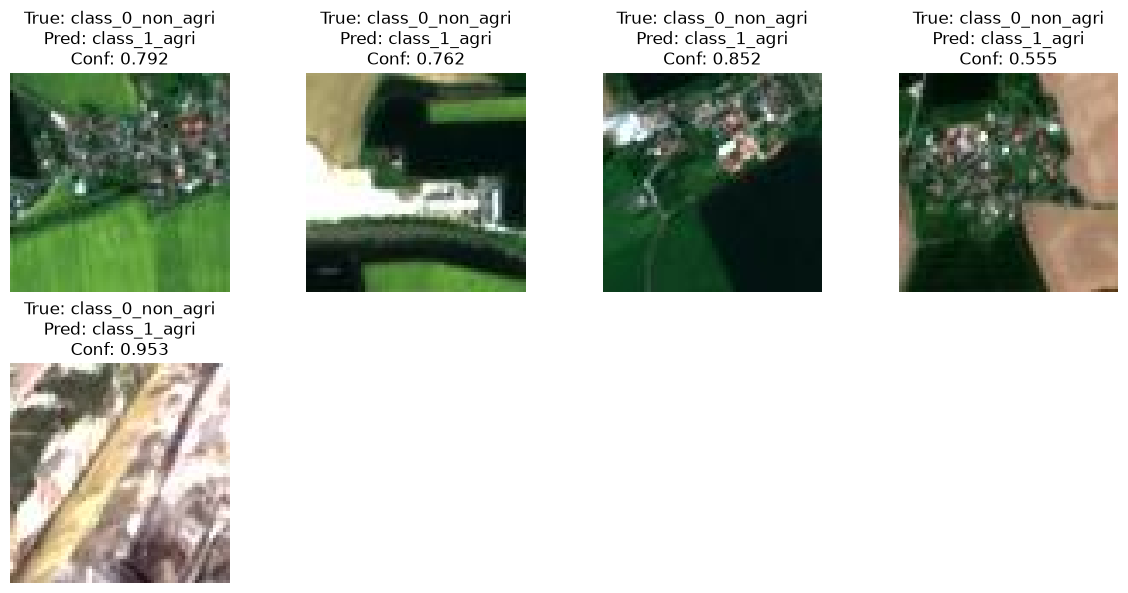

In [14]:
import math
import numpy as np
import matplotlib.pyplot as plt

n = len(misclassified_images)

if n == 0:
    print("No misclassified images!")
else:
    cols = min(4, n)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(12, 3 * rows))

    for i in range(n):
        ax = plt.subplot(rows, cols, i + 1)

        # Convert normalized [-1, 1] -> [0, 255]
        image = (misclassified_images[i] + 1.0) * 127.5
        image = np.clip(image, 0, 255).astype(np.uint8)

        ax.imshow(image)

        ax.set_title(
            f"True: {class_names[misclassified_true[i]]}\n"
            f"Pred: {class_names[misclassified_pred[i]]}\n"
            f"Conf: {misclassified_conf[i]:.3f}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()